# 05_model_evaluation: Evaluating the lagged regression models

**Project:** Spider-Sense: A Time-Series Analysis of Housing Market Factors in Charlottesville
**Course:** DS 4002, Section 001 | **Team:** Dataverse
**Author:** Hershi Aytoda | **Date:** October 22, 2026

## Purpose
This notebook proceeds "04_regression_models" file in the `SCRIPTS/` folder. This notebook evaluates the two lagged regression models fit in the model-fitting notebook (long-run: 1991-2026, recent: 2018-2026). It:
1. Plots the results (actual vs. fitted, coefficients with 95% CIs, lag reliability).
2. Runs residual diagnostics and robustness checks on the significance results.
3. Runs an outlier analysis: which quarters are most influential, and do the results survive when the 2008-09 recession and the 2020-22 pandemic period are handled?
4. Saves formatted results tables.

## Where this fits in the pipeline (run in numeric order)
| Step | Script | Output |
|---|---|---|
| 1 | Data download and preprocessing | `DATA/cleaned_quarterly.csv` |
| 2 | Exploratory analysis (R) | exploratory plots and tables |
| 3 | Model fitting notebook | model results in `OUTPUT/` |
| 4 | **This notebook** | `OUTPUT/` and `OUTPUT/EVALUATION_TABLES/` |

## Inputs
* `DATA/cleaned_quarterly.csv`: cleaned quarterly data (cloned from the GitHub repo below).
* From the model-fitting step, in `OUTPUT/`: `11_lag_correlations.csv`, `12_lag_stability.csv`, `13_results_table.csv`, `14_model_summary.csv`, `17_long_run_fitted_residuals.csv`, `18_recent_fitted_residuals.csv`.

## How to run
1. Open this notebook in Google Colab.
2. Choose **Runtime > Run all**. The repo is cloned automatically; no files need to be uploaded.
3. Figures and tables are saved in the Colab file browser under `DS4002-Project2/OUTPUT/`. The last cell zips them for download.

## Important notes
* No random numbers are used, so results are exactly reproducible.
* The models are **refit** here from the cleaned data and the lags chosen in the model-fitting step, and checked against the saved `13_results_table.csv`.
* Lags were chosen on the same data used to fit the models, so all p-values are **exploratory**.
* Results describe **associations, not causes**.

## 1. Setup
Load the packages used throughout the notebook and print their versions for the record.

In [1]:
# Standard library
import platform
import subprocess
import zipfile
from pathlib import Path

# Data handling and numerics
import numpy as np
import pandas as pd

# Plotting
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display, Image

# Statistics
import statsmodels
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_ljungbox

# Show numbers in printed tables with 4 decimal places
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| statsmodels", statsmodels.__version__, "| matplotlib", matplotlib.__version__)

Python 3.13.16 | numpy 2.1.3 | pandas 2.2.3 | statsmodels 0.15.0 | matplotlib 3.10.0


## 2. Settings and file locations
The project repo is cloned from GitHub so the notebook runs the same way on any computer. The model-fitting outputs are read from the repo's `OUTPUT/` folder (or from `/content/OUTPUT` if the model-fitting notebook was just run in this same Colab session).

In [2]:
# ---- Repository -----------------------------------------------------
REPO_URL  = "https://github.com/hershiaytoda/DS4002-Project2.git"
REPO_NAME = "DS4002-Project2"

# Are we running inside Google Colab?
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Project folder: /content/<repo> in Colab; otherwise the nearest folder
# (here or above) that contains DATA/, falling back to a fresh clone here.
if IN_COLAB:
    ROOT = Path("/content") / REPO_NAME
else:
    ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "DATA").is_dir()),
                Path.cwd() / REPO_NAME)

# Clone the repo if the project folder is not there yet.
if not (ROOT / "DATA").is_dir():
    subprocess.run(["git", "clone", REPO_URL, str(ROOT)], check=True)

# ---- Folders ---------------------------------------------------------
DATA_PATH  = ROOT / "DATA" / "cleaned_quarterly.csv"
OUTPUT_DIR = ROOT / "OUTPUT"
FIG_DIR    = OUTPUT_DIR             # figures made by this notebook
TABLE_DIR  = OUTPUT_DIR / "EVALUATION_TABLES"   # tables made by this notebook
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Cannot find {DATA_PATH}. Check that DATA/cleaned_quarterly.csv is in the repo.")

# ---- Where are the model-fitting outputs? ---------------------------
REQUIRED = ["11_lag_correlations.csv", "12_lag_stability.csv", "13_results_table.csv",
            "14_model_summary.csv", "17_long_run_fitted_residuals.csv", "18_recent_fitted_residuals.csv"]
INPUT_DIR = next((d for d in [OUTPUT_DIR, Path("/content/OUTPUT")]
                  if all((d / f).exists() for f in REQUIRED)), None)
if INPUT_DIR is None:
    raise FileNotFoundError(
        f"Model-fitting outputs {REQUIRED} not found in {OUTPUT_DIR}. "
        "Run the model-fitting notebook and commit its OUTPUT/ files to the repo first.")

print("Project folder:  ", ROOT)
print("Model results from:", INPUT_DIR)
print("Saving figures to: ", FIG_DIR)
print("Saving tables to:  ", TABLE_DIR)

Project folder:   /content/DS4002-Project2
Model results from: /content/DS4002-Project2/OUTPUT
Saving figures to:  /content/DS4002-Project2/OUTPUT/figures
Saving tables to:   /content/DS4002-Project2/OUTPUT/evaluation_tables


In [3]:
# ---- Column names (must match the model-fitting step) ---------------
DATE_COL = "quarter"          # e.g. "2017Q3"
OUTCOME  = "hpi_yoy_pct"      # YoY % change in the house price index

# Predictors in each model
MODEL_PREDICTORS = {
    "long_run": ["unemployment_rate_yoy_pp", "mortgage_rate_yoy_pp"],
    "recent":   ["unemployment_rate_yoy_pp", "mortgage_rate_yoy_pp", "active_listings_yoy_pct"],
}
MODEL_LABELS = {"long_run": "Long-run model (1991-2026)", "recent": "Recent model (2018-2026)"}
PREDICTOR_ORDER = ["mortgage_rate_yoy_pp", "unemployment_rate_yoy_pp", "active_listings_yoy_pct"]
PRETTY = {"mortgage_rate_yoy_pp": "Mortgage rate (YoY pp)",
          "unemployment_rate_yoy_pp": "Unemployment (YoY pp)",
          "active_listings_yoy_pct": "Active listings (YoY %)"}

# ---- Analysis parameters (same as the model-fitting step / MI2) ------
NW_LAGS = 4            # Newey-West maximum lag used for the main results
ALPHA   = 0.05         # two-sided significance level
MAX_LAG = 4            # lags 0-4 were tested
HAC_LAGS_TO_TEST = [6, 8]   # extra Newey-West lags used in the robustness check

# ---- Crisis periods used for shading and the outlier analysis --------
SHADED = [("2008Q1", "2009Q2", "Great Recession"), ("2020Q1", "2020Q2", "COVID shock")]
CRISIS = {"recession_2007Q4_2009Q2": ("2007Q4", "2009Q2"),   # NBER recession dates
          "pandemic_2020Q1_2022Q4":  ("2020Q1", "2022Q4")}   # pandemic shock and aftermath

BLUE, RED = "#2b6cb0", "#c53030"

## 3. Helper functions
Small functions reused by the figures and tables below.

In [4]:
def pretty_term(term):
    """Turn a column name like 'mortgage_rate_yoy_pp_lag0' into a readable label."""
    if term == "const":
        return "Intercept"
    base, lag = term.rsplit("_lag", 1)           # split off the lag number
    return f"{PRETTY.get(base, base)}, lag {lag}"


def to_dates(quarters):
    """Convert quarter labels (e.g. '2017Q3') to timestamps for plotting."""
    return pd.PeriodIndex(quarters, freq="Q").to_timestamp()


def add_shading(ax):
    """Shade the recession and COVID periods on a time-axis plot."""
    for start, end, label in SHADED:
        ax.axvspan(pd.Period(start, "Q").to_timestamp(), pd.Period(end, "Q").to_timestamp(how="end"),
                   color="grey", alpha=0.25, label=label)


def save_fig(fig, name):
    """Save a figure into FIG_DIR as a PNG, show it in the notebook, and close it."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    display(Image(filename=str(path)))
    plt.close(fig)
    print("Saved figure:", path.name)


def save_table_png(table, name, title, col_width=1.7):
    """Render a pandas table as a PNG image (handy for the GitHub README)."""
    table = table.astype(str)
    fig, ax = plt.subplots(figsize=(max(6, col_width * len(table.columns)), 0.45 * (len(table) + 2)))
    ax.axis("off")
    tbl = ax.table(cellText=table.values, colLabels=table.columns, loc="center", cellLoc="center")
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(9)
    tbl.scale(1, 1.4)
    ax.set_title(title, fontweight="bold")
    fig.savefig(TABLE_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.close(fig)
    print("Saved table image:", f"{name}.png")


def fmt_p(p):
    """Format a p-value for display."""
    return "<0.001" if p < 0.001 else f"{p:.3f}"


def tidy(model, spec, name):
    """Collect a fitted model's coefficients, CIs, and p-values into one table."""
    ci = model.conf_int(alpha=ALPHA)
    return pd.DataFrame({
        "model": name, "spec": spec, "term": model.params.index,
        "coefficient": model.params.values, "std_error": model.bse.values,
        "ci_95_low": ci[0].values, "ci_95_high": ci[1].values,
        "p_value": model.pvalues.values, "n_quarters": int(model.nobs),
        "adj_R2": model.rsquared_adj})

## 4. Load the data and the model-fitting results
* The cleaned data is placed on a continuous quarterly calendar so that shifting a column by *k* rows always means *k* calendar quarters (missing quarters stay as blank rows).
* The saved results tables from the model-fitting step are read in for plotting.

In [5]:
# Results saved by the model-fitting step
lag_corr  = pd.read_csv(INPUT_DIR / "11_lag_correlations.csv")
stability = pd.read_csv(INPUT_DIR / "12_lag_stability.csv")
results   = pd.read_csv(INPUT_DIR / "13_results_table.csv")
summary   = pd.read_csv(INPUT_DIR / "14_model_summary.csv")
# Make sure 'selected' is a true/false column however it was saved.
lag_corr["selected"] = lag_corr["selected"].astype(str).str.lower().eq("true")

# Quarter-by-quarter actual, fitted, and residual values for each model
fits = {name: pd.read_csv(INPUT_DIR / {"long_run": "17_long_run_fitted_residuals.csv", "recent": "18_recent_fitted_residuals.csv"}[name]) for name in MODEL_PREDICTORS}
for f in fits.values():
    f["date"] = to_dates(f["quarter"])

# Cleaned quarterly data, one row per calendar quarter
df = pd.read_csv(DATA_PATH)
df.index = pd.PeriodIndex(df.pop(DATE_COL).astype(str), freq="Q")
df = df.sort_index()
needed = [OUTCOME, *dict.fromkeys(sum(MODEL_PREDICTORS.values(), []))]
missing_cols = [c for c in needed if c not in df.columns]
if missing_cols:
    raise KeyError(f"Columns {missing_cols} not found. Columns are: {list(df.columns)}")
df = df[needed].reindex(pd.period_range(df.index.min(), df.index.max(), freq="Q"))
print(f"Cleaned data: {df.index.min()} to {df.index.max()} ({len(df)} quarters)")

Cleaned data: 1983Q3 to 2026Q2 (172 quarters)


## 5. Refit the models
The models are rebuilt exactly as in the model-fitting step: each predictor is shifted by its selected lag, rows are limited to quarters where every variable exists, predictors are standardized (mean 0, SD 1), and OLS is fit with Newey-West (HAC) standard errors. The refit coefficients are checked against the saved `13_results_table.csv`; a mismatch prints a warning.

In [6]:
def selected_lags(model_name):
    """Read the lag chosen for each predictor from the saved lag table."""
    t = lag_corr[(lag_corr["model"] == model_name) & (lag_corr["selected"])]
    return dict(zip(t["predictor"], t["lag_quarters"].astype(int)))


def window(d):
    """First and last quarter in which all of a model's variables are present."""
    complete = d.dropna()
    return complete.index.min(), complete.index.max()


def build_model_data(selected, win):
    """Shift each predictor by its selected lag, keep complete quarters in the
    model window, and standardize predictors (mean 0, SD 1) on that sample."""
    X = pd.DataFrame({f"{p}_lag{k}": df[p].shift(k) for p, k in selected.items()})
    data = pd.concat([df[OUTCOME], X], axis=1).loc[win[0]:win[1]].dropna()
    y = data[OUTCOME]
    X_raw = data.drop(columns=OUTCOME)
    X_std = (X_raw - X_raw.mean()) / X_raw.std()
    return y, X_std


def fit_model(y, X, maxlags=NW_LAGS, correction=False):
    """OLS with an intercept and Newey-West (HAC) standard errors.
    maxlags    = Newey-West maximum lag
    correction = apply a small-sample correction to the standard errors
    use_t=True makes coefficient tests two-sided t-tests."""
    return sm.OLS(y, sm.add_constant(X)).fit(
        cov_type="HAC", cov_kwds={"maxlags": maxlags, "use_correction": correction}, use_t=True)


models = {}
for name, preds in MODEL_PREDICTORS.items():
    win = window(df[[OUTCOME, *preds]])
    lags = selected_lags(name)
    y, X = build_model_data(lags, win)
    fit = fit_model(y, X)
    models[name] = {"y": y, "X": X, "lags": lags, "fit": fit}

    # Reproducibility check: refit coefficients should match the saved results.
    saved = results[results["model"] == name].set_index("term")["std_coefficient"]
    if np.allclose(fit.params.reindex(saved.index).values, saved.values, atol=1e-4):
        print(f"{name}: refit matches 13_results_table.csv (n = {int(fit.nobs)}, "
              f"{y.index.min()} to {y.index.max()}, lags {lags})")
    else:
        print(f"WARNING: {name} refit does NOT match 13_results_table.csv. "
              "Check that the data and settings match the model-fitting step.")

long_run: refit matches results_table.csv (n = 140, 1991Q2 to 2026Q2, lags {'unemployment_rate_yoy_pp': 1, 'mortgage_rate_yoy_pp': 0})
recent: refit matches results_table.csv (n = 31, 2018Q3 to 2026Q2, lags {'unemployment_rate_yoy_pp': 1, 'mortgage_rate_yoy_pp': 0, 'active_listings_yoy_pct': 4})


## 6. Results figures

### Figure 1: Actual vs. fitted price growth
Black is real year-over-year price growth; the red dashed line is the model's fit. Gaps show where the model misses. Grey bands mark 2008-09 and 2020.

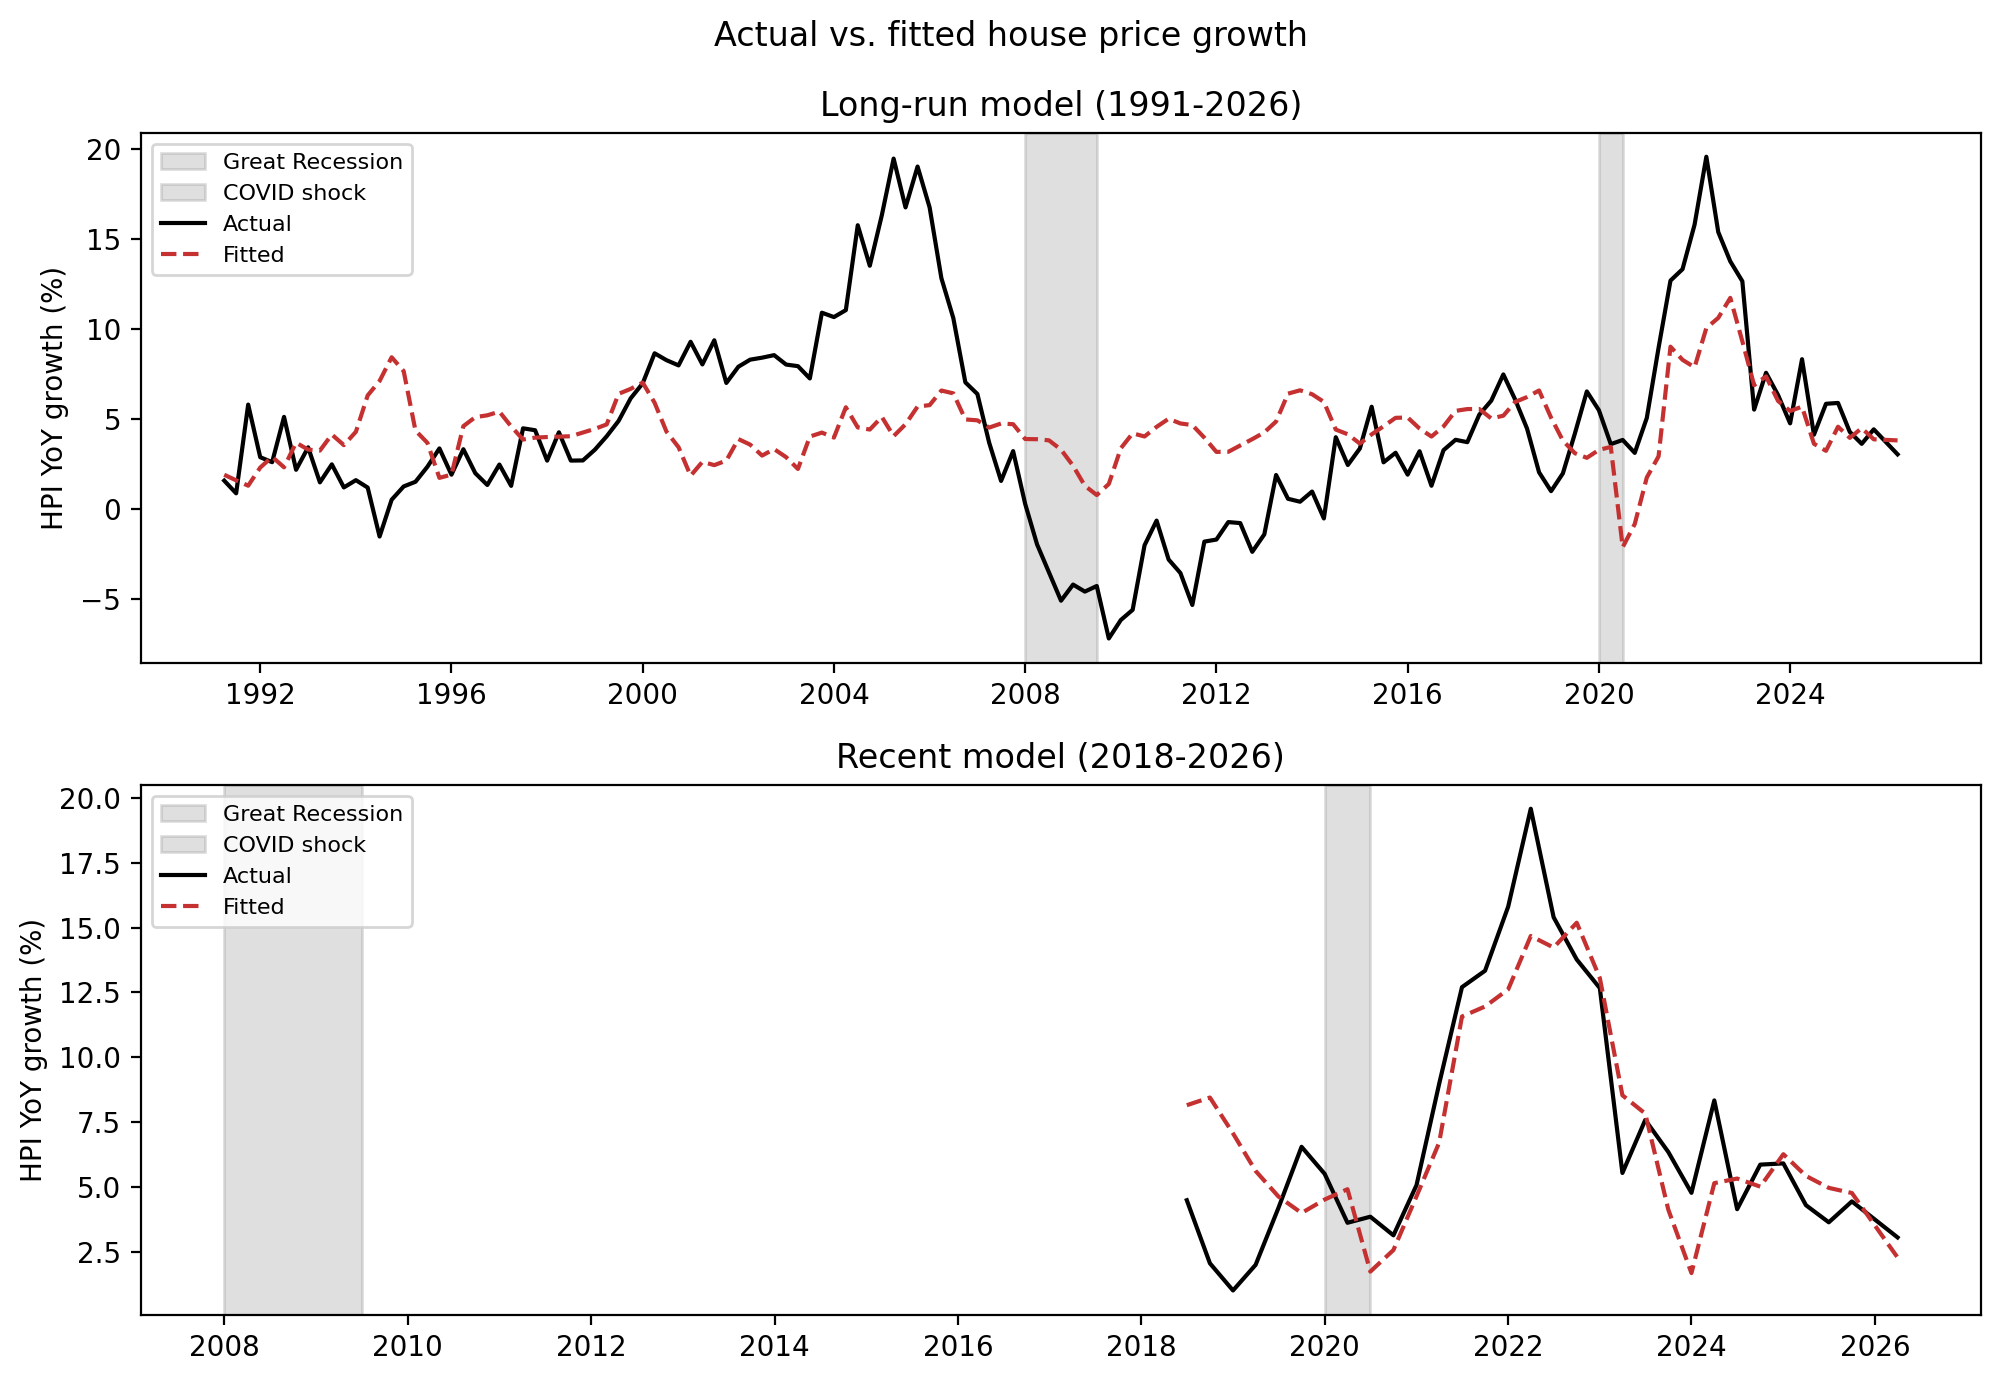

Saved figure: 01_actual_vs_fitted.png


In [7]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7))
for ax, (name, label) in zip(axes, MODEL_LABELS.items()):
    f = fits[name]
    add_shading(ax)
    ax.plot(f["date"], f["actual"], color="black", label="Actual")
    ax.plot(f["date"], f["fitted"], color=RED, ls="--", label="Fitted")
    ax.set_title(label)
    ax.set_ylabel("HPI YoY growth (%)")
    ax.legend(loc="upper left", fontsize=8)
fig.suptitle("Actual vs. fitted house price growth")
fig.tight_layout()
save_fig(fig, "19_actual_vs_fitted")

### Figure 2: Coefficient plot with 95% confidence intervals
Each dot is the estimated change in HPI growth (percentage points) for a 1-standard-deviation change in the predictor, holding the others fixed. A line that crosses zero means the effect is not significantly different from zero (grey). Rows are ordered by size of the standardized coefficient, but overlapping intervals mean the ordering is descriptive, not proven.

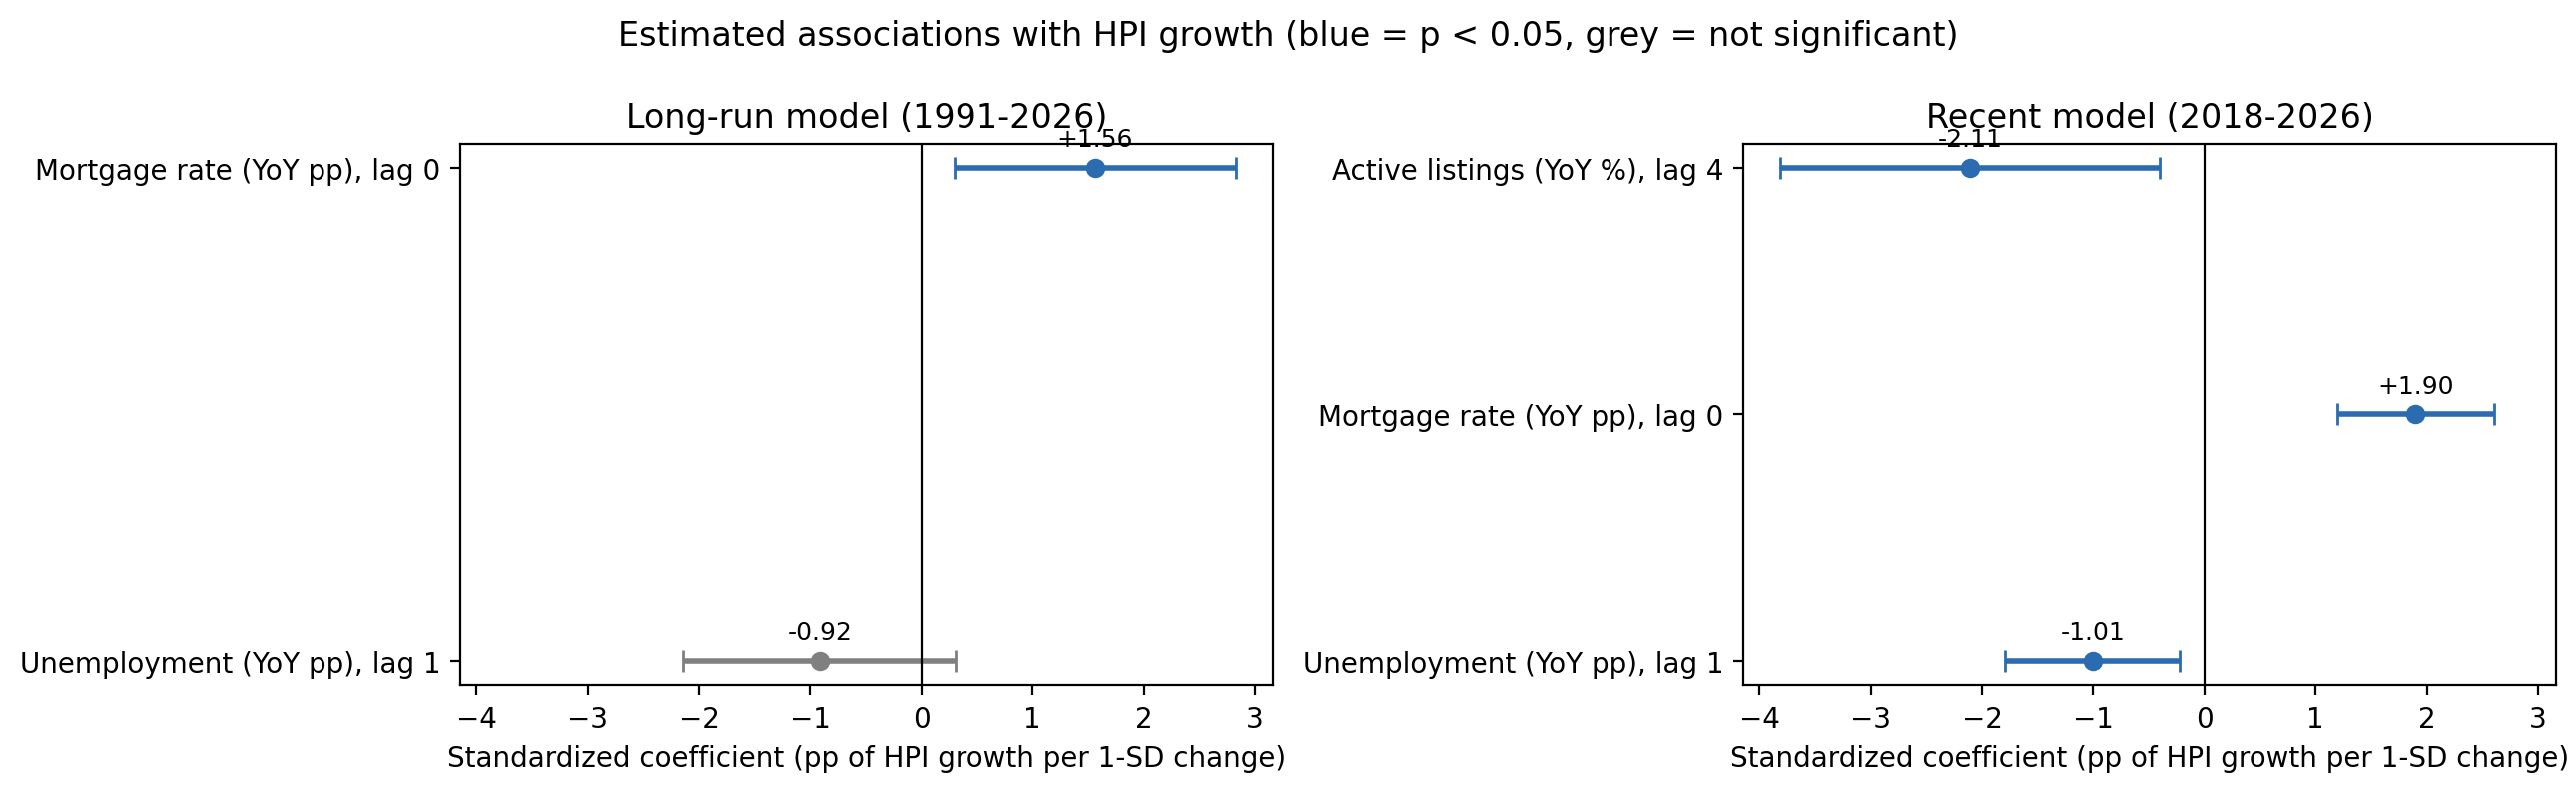

Saved figure: 02_coefficient_plot.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True)
for ax, (name, label) in zip(axes, MODEL_LABELS.items()):
    t = results[(results["model"] == name) & (results["term"] != "const")].sort_values("rank")
    ypos = np.arange(len(t))[::-1]                        # rank 1 at the top
    for yp, (_, r) in zip(ypos, t.iterrows()):
        color = BLUE if r["significant"] else "grey"
        ax.errorbar(r["std_coefficient"], yp,
                    xerr=[[r["std_coefficient"] - r["ci_95_low"]], [r["ci_95_high"] - r["std_coefficient"]]],
                    fmt="o", color=color, capsize=4, lw=2)
        ax.annotate(f"{r['std_coefficient']:+.2f}", (r["std_coefficient"], yp),   # print the estimate
                    textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_yticks(ypos)
    ax.set_yticklabels([pretty_term(x) for x in t["term"]])
    ax.set_xlabel("Standardized coefficient (pp of HPI growth per 1-SD change)")
    ax.set_title(label)
fig.suptitle("Estimated associations with HPI growth (blue = p < 0.05, grey = not significant)")
fig.tight_layout()
save_fig(fig, "20_coefficient_plot")

### Figure 3: How reliable is each selected lag?
For each predictor, the lag with the strongest correlation was selected. Because year-over-year changes overlap, neighboring lags look similar, so the model-fitting step re-ran the lag selection on 2,000 block-bootstrap resamples (blocks of 8 consecutive quarters). Bars show how often each lag won; blue is the selected lag and the dashed line is 70%, the cutoff used to call a lag "clear". Spread-out bars mean the timing is uncertain and should be reported as a range.

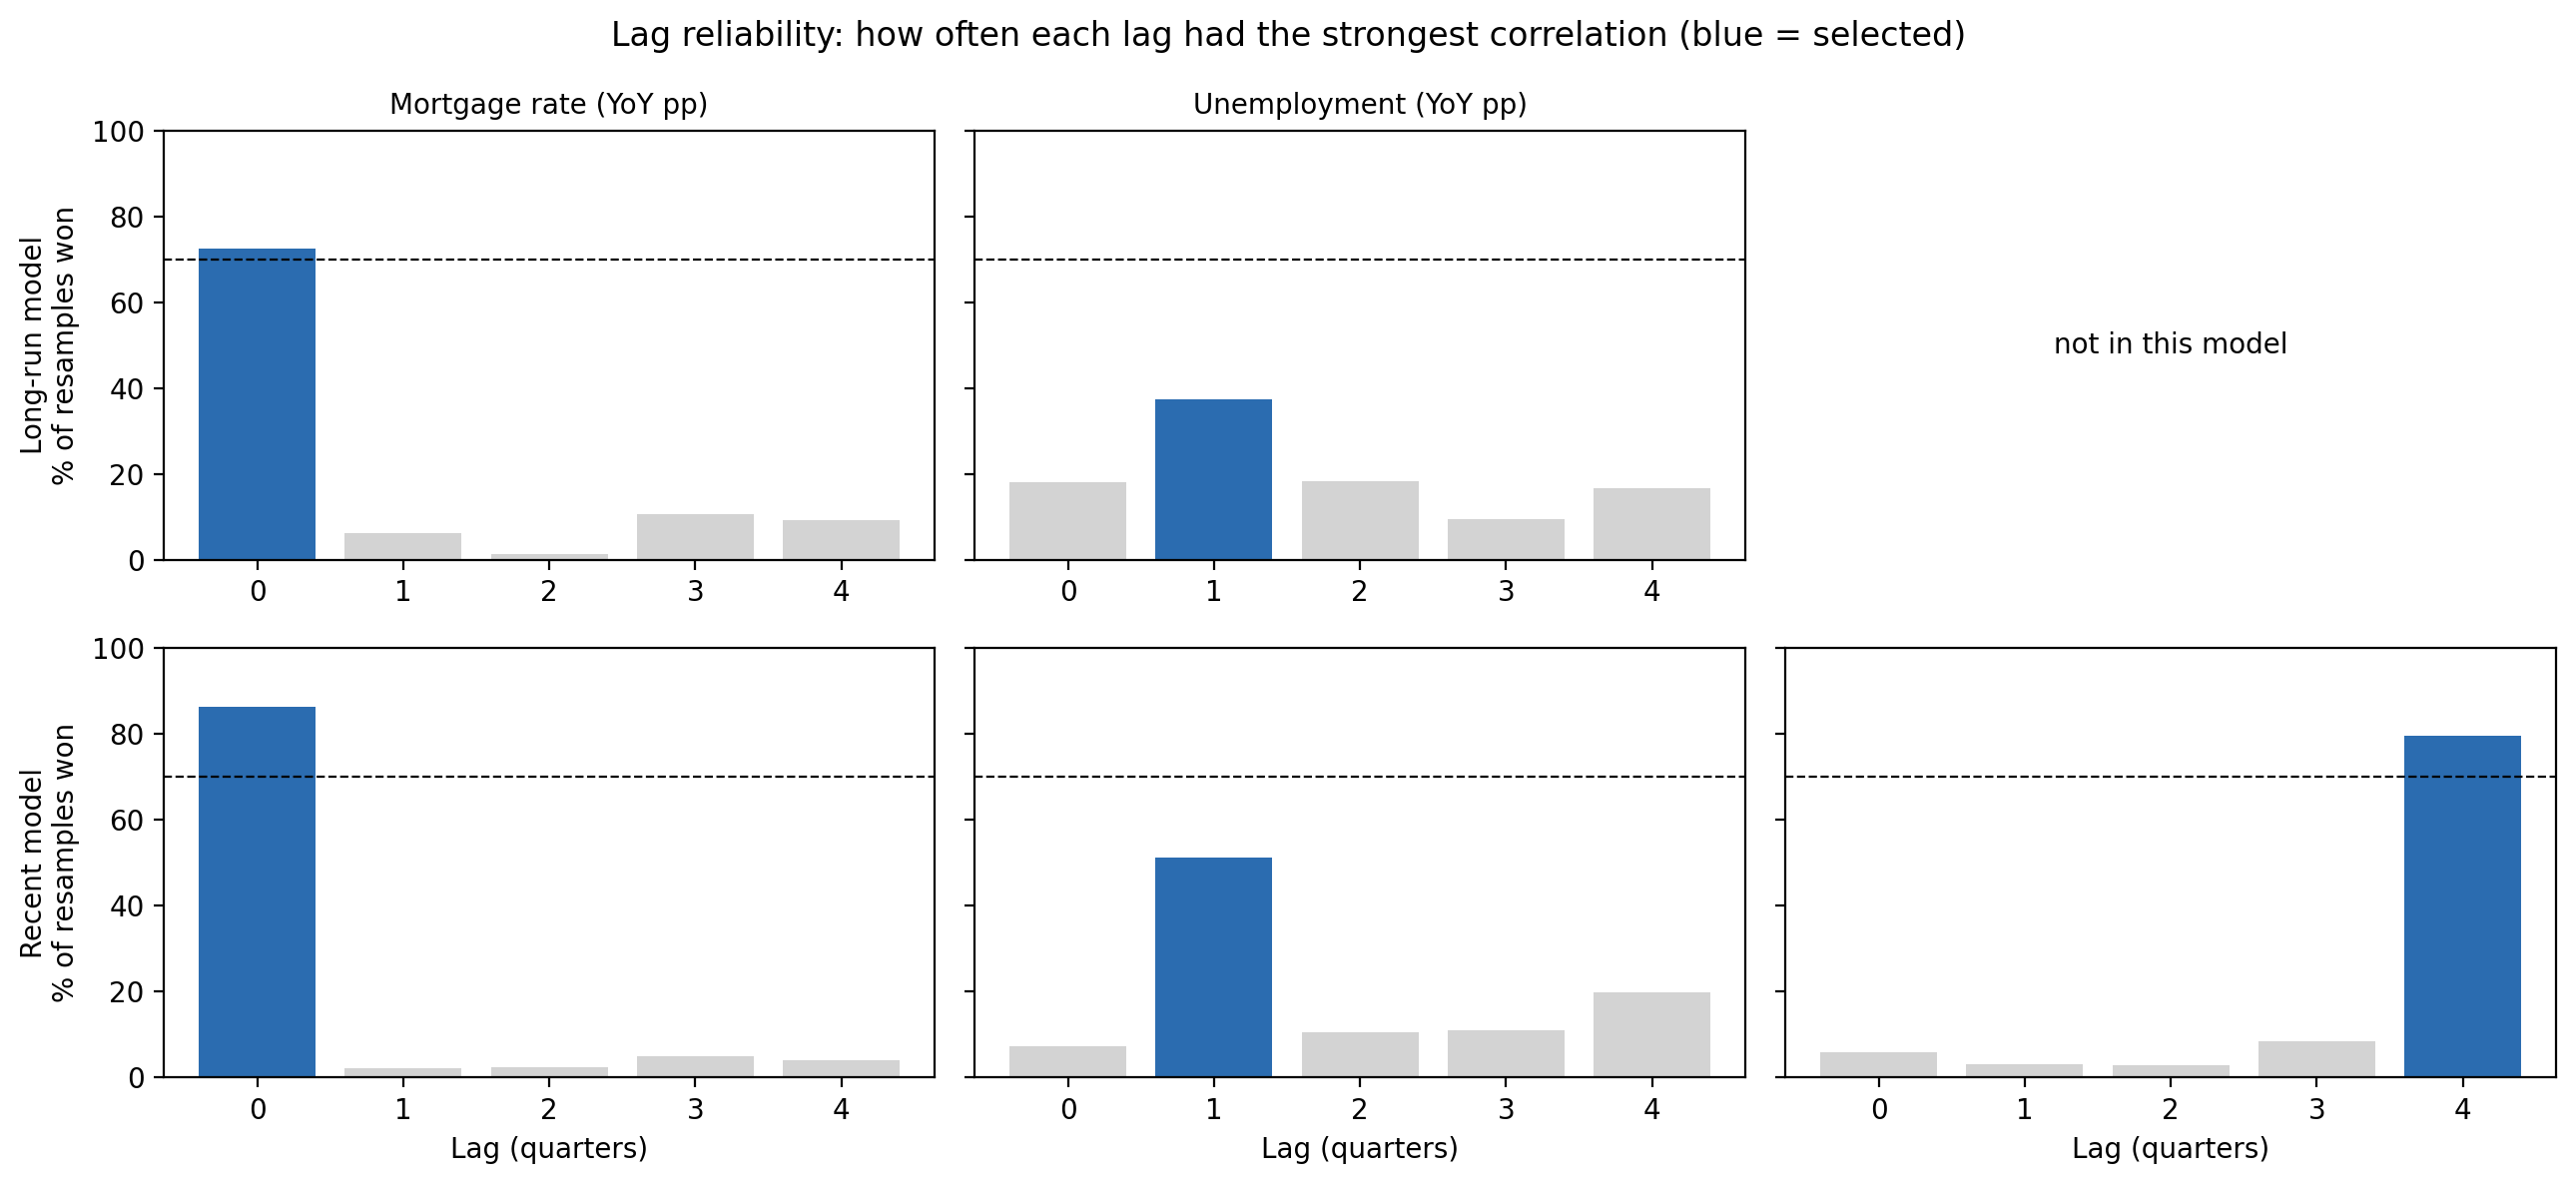

Saved figure: 03_lag_stability.png


In [9]:
win_cols = [f"lag{k}_%" for k in range(MAX_LAG + 1)]
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharey=True)
for i, name in enumerate(MODEL_PREDICTORS):
    for j, p in enumerate(PREDICTOR_ORDER):
        ax = axes[i, j]
        t = stability[(stability["model"] == name) & (stability["predictor"] == p)]
        if t.empty:                                        # listings are not in the long-run model
            ax.axis("off")
            ax.text(0.5, 0.5, "not in this model", ha="center", va="center", transform=ax.transAxes)
            continue
        r = t.iloc[0]
        ax.bar(range(MAX_LAG + 1), [r[c] for c in win_cols],
               color=[BLUE if k == r["selected_lag"] else "lightgrey" for k in range(MAX_LAG + 1)])
        ax.axhline(70, color="black", ls="--", lw=0.8)
        ax.set_xticks(range(MAX_LAG + 1))
        ax.set_ylim(0, 100)
        ax.set_title(PRETTY[p] if i == 0 else "", fontsize=10)
        if j == 0:
            ax.set_ylabel(f"{MODEL_LABELS[name].split(' (')[0]}\n% of resamples won")
        if i == 1:
            ax.set_xlabel("Lag (quarters)")
fig.suptitle("Lag reliability: how often each lag had the strongest correlation (blue = selected)")
fig.tight_layout()
save_fig(fig, "21_lag_stability")

### Figure 4: Mortgage-rate changes and price growth over time
Shows the co-movement behind the positive mortgage coefficient: the two series tend to rise together (for example around 2021-22).

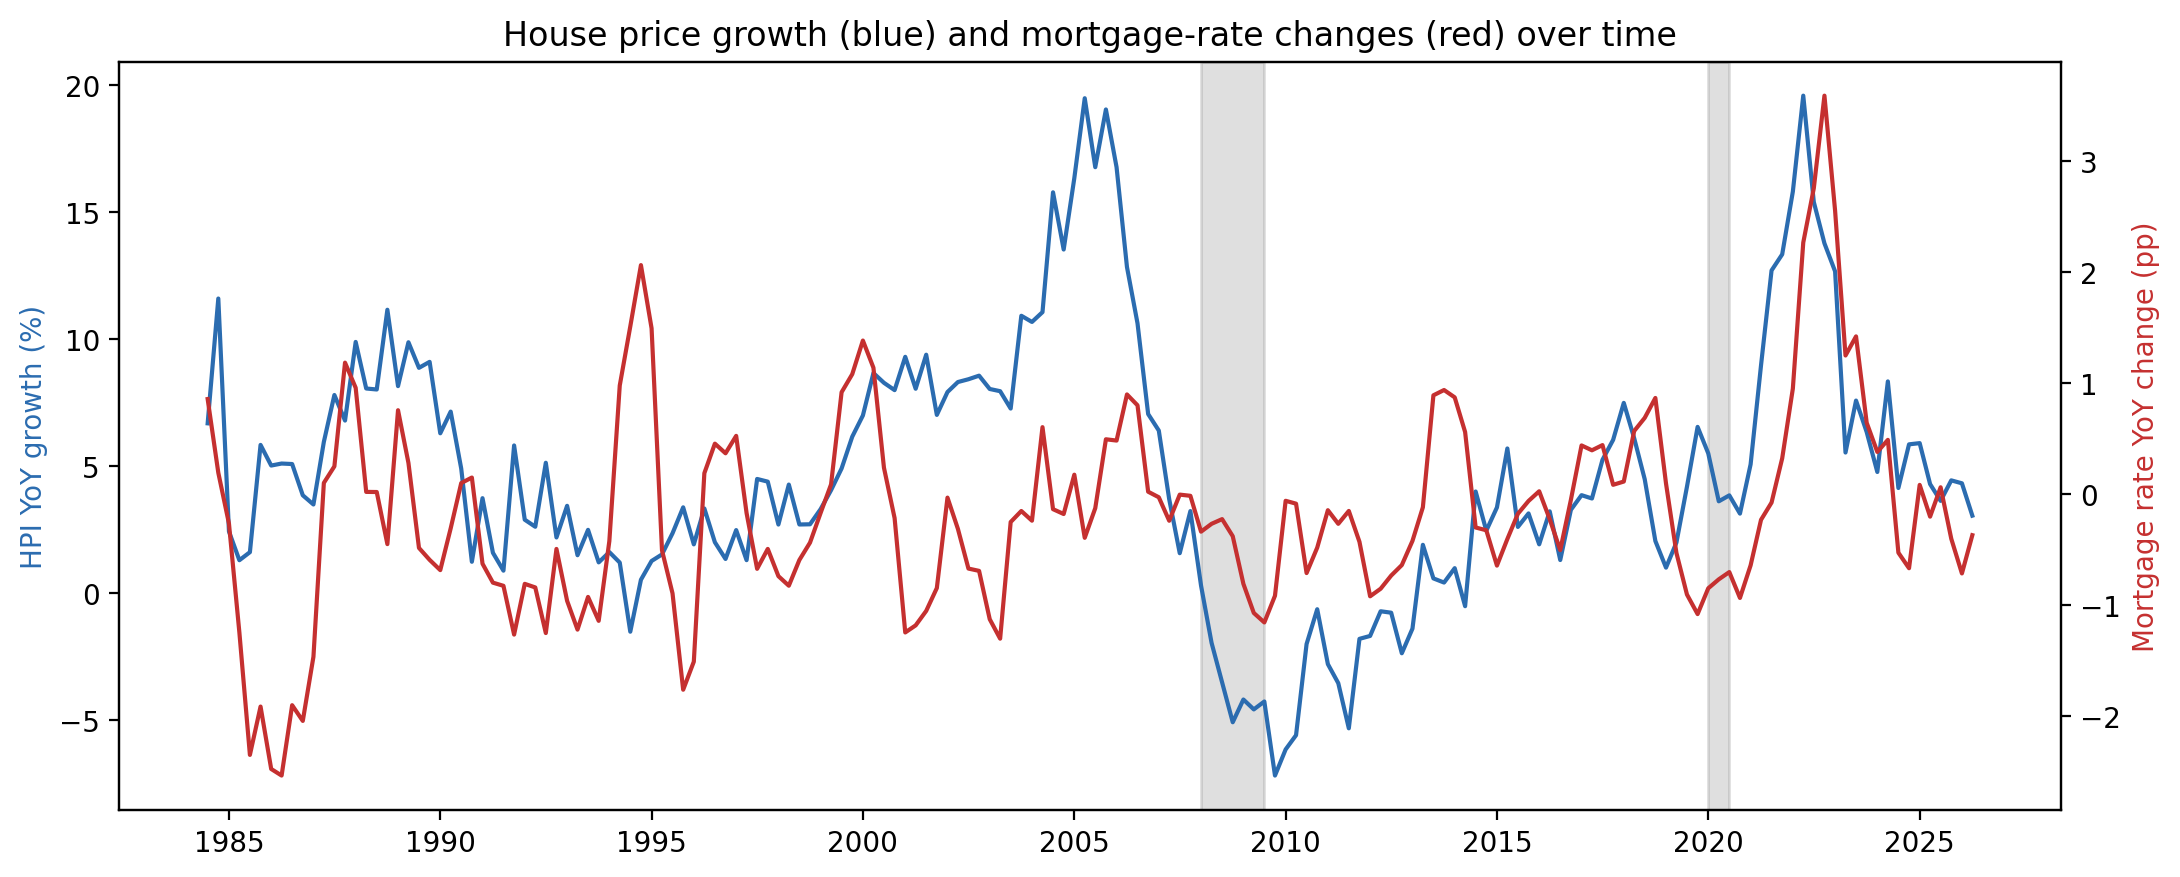

Saved figure: 04_mortgage_vs_hpi_growth.png


In [10]:
ts = df.dropna(subset=[OUTCOME, "mortgage_rate_yoy_pp"])
fig, ax1 = plt.subplots(figsize=(11, 4.5))
add_shading(ax1)
ax1.plot(ts.index.to_timestamp(), ts[OUTCOME], color=BLUE)
ax1.set_ylabel("HPI YoY growth (%)", color=BLUE)
ax2 = ax1.twinx()                                          # second y-axis for the mortgage series
ax2.plot(ts.index.to_timestamp(), ts["mortgage_rate_yoy_pp"], color=RED)
ax2.set_ylabel("Mortgage rate YoY change (pp)", color=RED)
ax1.set_title("House price growth (blue) and mortgage-rate changes (red) over time")
fig.tight_layout()
save_fig(fig, "22_mortgage_vs_hpi_growth")

## 7. Residual diagnostics
Classical checks on the model residuals (plain OLS residuals; the coefficients are identical to the Newey-West fit, only the standard errors differ).

| Column | What it checks | Reading |
|---|---|---|
| `durbin_watson` | autocorrelation in the residuals | near 2 is fine; near 0 means strong positive autocorrelation |
| `ljung_box_p_lag4/8` | leftover autocorrelation | small p (< 0.05) means errors are related across quarters |
| `breusch_pagan_p` | constant variance | small p means unequal variance |
| `jarque_bera_p` | normal residuals | small p means non-normal residuals |
| `max_VIF` | overlap between predictors | above 5 is a concern |

Autocorrelation is expected with overlapping year-over-year data, which is why Newey-West standard errors are used.

In [11]:
diag_rows = []
for name, m in models.items():
    ols = sm.OLS(m["y"], sm.add_constant(m["X"])).fit()          # plain OLS for classical tests
    resid = ols.resid
    jb, jb_p, skew, kurt = jarque_bera(resid)                      # normality of residuals
    bp_lm, bp_p, _, _ = het_breuschpagan(resid, ols.model.exog)    # constant variance
    lb = acorr_ljungbox(resid, lags=[4, 8], return_df=True)        # leftover autocorrelation
    max_vif = results[(results["model"] == name) & (results["term"] != "const")]["VIF"].max()
    diag_rows.append({
        "model": name, "n_quarters": int(ols.nobs),
        "durbin_watson": durbin_watson(resid),
        "ljung_box_p_lag4": lb.loc[4, "lb_pvalue"],
        "ljung_box_p_lag8": lb.loc[8, "lb_pvalue"],
        "breusch_pagan_p": bp_p,
        "jarque_bera_p": jb_p,
        "max_VIF": max_vif,
    })

diagnostics = pd.DataFrame(diag_rows)
diagnostics.to_csv(TABLE_DIR / "02_diagnostics.csv", index=False)
diagnostics

,model,n_quarters,durbin_watson,ljung_box_p_lag4,ljung_box_p_lag8,breusch_pagan_p,jarque_bera_p,max_VIF
0,long_run,140,0.1989,0.0000,0.0000,0.4641,0.0961,1.0442
1,recent,31,0.6642,0.0019,0.0217,0.7939,0.3000,1.3245


## 8. Robustness checks on significance
These checks ask whether the significance results depend on analysis choices.

* **Newey-West settings:** the main results use 4 lags. Here we add a small-sample correction and longer windows (6 and 8 lags).
* **No-listings model:** the recent model refit without active listings, on exactly the same quarters. Comparing it with the full recent model separates the effect of the shorter window from the effect of adding listings.
* **Equal-strength tests:** do two predictors' coefficients really differ in size? A large p-value means the ranking of those two predictors is only descriptive.

If a predictor stays significant across versions, the result is sturdy; if its p-value crosses 0.05, it is fragile.

In [12]:
spec_nolist = "recent window, no listings (same quarters)"

robust = []
for name, m in models.items():
    y, X = m["y"], m["X"]
    robust.append(tidy(m["fit"], "baseline: Newey-West 4 lags", name))
    # (a) Small-sample correction on the standard errors
    robust.append(tidy(fit_model(y, X, NW_LAGS, correction=True),
                       "Newey-West 4 lags + small-sample correction", name))
    # (b) Longer Newey-West windows (more allowance for autocorrelation)
    for L in HAC_LAGS_TO_TEST:
        robust.append(tidy(fit_model(y, X, L), f"Newey-West {L} lags", name))

# (c) Recent-window model WITHOUT listings, on exactly the same quarters
m = models["recent"]
no_list_cols = [c for c in m["X"].columns if not c.startswith("active_listings")]
robust.append(tidy(fit_model(m["y"], m["X"][no_list_cols]), spec_nolist, "recent"))

robustness = pd.concat(robust, ignore_index=True)
robustness.to_csv(TABLE_DIR / "10_robustness_checks.csv", index=False)

# p-values for each predictor under every specification, side by side
p_compare = (robustness[robustness["term"] != "const"]
             .pivot_table(index=["model", "term"], columns="spec", values="p_value", sort=False))
p_compare.to_csv(TABLE_DIR / "11_robustness_p_values.csv")
print("P-values under different specifications (look for p crossing 0.05):")
print(p_compare.round(3).to_string())

# Adjusted R-squared with and without listings (same quarters)
r2_compare = robustness[robustness["spec"].isin(["baseline: Newey-West 4 lags", spec_nolist]) &
                        (robustness["model"] == "recent")][["spec", "adj_R2", "n_quarters"]].drop_duplicates()
print("\nRecent model: adjusted R-squared with vs. without listings:")
print(r2_compare.to_string(index=False))

P-values under different specifications (look for p crossing 0.05):
spec                                    baseline: Newey-West 4 lags  Newey-West 4 lags + small-sample correction  Newey-West 6 lags  Newey-West 8 lags  recent window, no listings (same quarters)
model    term                                                                                                                                                                                     
long_run unemployment_rate_yoy_pp_lag1                       0.1420                                       0.1460             0.1200             0.1000                                         NaN
         mortgage_rate_yoy_pp_lag0                           0.0160                                       0.0170             0.0190             0.0230                                         NaN
recent   unemployment_rate_yoy_pp_lag1                       0.0140                                       0.0210             0.0100             0.0110  

In [13]:
# Equal-strength tests between predictors.
# Opposite-signed coefficients are equally strong when a + b = 0; same-signed when a - b = 0.
wald_rows = []
for name, m in models.items():
    terms = list(m["X"].columns)
    for i in range(len(terms)):
        for j in range(i + 1, len(terms)):
            a, b = terms[i], terms[j]
            sign = "+" if m["fit"].params[a] * m["fit"].params[b] < 0 else "-"
            test = m["fit"].wald_test(f"{a} {sign} {b} = 0", scalar=True)
            wald_rows.append({"model": name, "predictor_A": pretty_term(a), "predictor_B": pretty_term(b),
                              "coef_A": m["fit"].params[a], "coef_B": m["fit"].params[b],
                              "p_equal_strength": float(test.pvalue)})
wald = pd.DataFrame(wald_rows)
wald.to_csv(TABLE_DIR / "03_equal_strength_tests.csv", index=False)
print("Tests of equal strength between predictors (large p = cannot tell them apart):")
print(wald.to_string(index=False))

Tests of equal strength between predictors (large p = cannot tell them apart):
   model                   predictor_A                    predictor_B  coef_A  coef_B  p_equal_strength
long_run  Unemployment (YoY pp), lag 1  Mortgage rate (YoY pp), lag 0 -0.9156  1.5638            0.4066
  recent  Unemployment (YoY pp), lag 1  Mortgage rate (YoY pp), lag 0 -1.0064  1.8991            0.0367
  recent  Unemployment (YoY pp), lag 1 Active listings (YoY %), lag 4 -1.0064 -2.1070            0.2711
  recent Mortgage rate (YoY pp), lag 0 Active listings (YoY %), lag 4  1.8991 -2.1070            0.8498


## 9. Outlier analysis
Housing growth was unusual during the 2008-09 recession and the 2020-22 pandemic period. This section asks (1) which quarters are most influential on each fitted model, and (2) whether the results survive when those periods are handled.

### 9a. Which quarters are influential?
Four standard checks are computed for every quarter:

| Measure | What it captures | Flag rule |
|---|---|---|
| Cook's distance | overall pull of the quarter on the fitted model | > 4/n |
| Studentized residual | how badly the model misses the quarter | absolute value > 2 |
| Leverage | how unusual the quarter's predictor values are | > 2k/n |
| Max DFBETAS | largest pull on any single coefficient | > 2/sqrt(n) |

A quarter is **flagged** if it trips at least two checks. A flag is a reason to look closer, not proof of a problem.

In [14]:
rows = []
for name, m in models.items():
    ols = sm.OLS(m["y"], sm.add_constant(m["X"])).fit()         # plain OLS: same coefficients as the NW fit
    infl = ols.get_influence()
    n, k = int(ols.nobs), len(ols.params)
    dfb = pd.DataFrame(infl.dfbetas, columns=ols.params.index).drop(columns="const")
    out = pd.DataFrame({
        "model": name,
        "quarter": m["y"].index.astype(str),
        "cooks_d": infl.cooks_distance[0],
        "student_resid": infl.resid_studentized_external,
        "leverage": infl.hat_matrix_diag,
        "max_abs_dfbetas": dfb.abs().max(axis=1).values,
    })
    out["flag_cooks"]    = out["cooks_d"] > 4 / n
    out["flag_resid"]    = out["student_resid"].abs() > 2
    out["flag_leverage"] = out["leverage"] > 2 * k / n
    out["flag_dfbetas"]  = out["max_abs_dfbetas"] > 2 / np.sqrt(n)
    out["n_flags"] = out[["flag_cooks", "flag_resid", "flag_leverage", "flag_dfbetas"]].sum(axis=1)
    rows.append(out)

influence = pd.concat(rows, ignore_index=True)
influence.to_csv(TABLE_DIR / "08_influence_measures.csv", index=False)

flagged = (influence[influence["n_flags"] >= 2]
           .sort_values(["model", "cooks_d"], ascending=[True, False]))
flagged.to_csv(TABLE_DIR / "07_flagged_quarters.csv", index=False)
print("Quarters flagged by 2 or more checks:")
print(flagged.round(3).to_string(index=False))

Quarters flagged by 2 or more checks:
   model quarter  cooks_d  student_resid  leverage  max_abs_dfbetas  flag_cooks  flag_resid  flag_leverage  flag_dfbetas  n_flags
long_run  2020Q3   0.2340         1.3850    0.2690           0.8240        True       False           True          True        3
long_run  2022Q2   0.0900         1.9700    0.0660           0.4310        True       False           True          True        3
long_run  2021Q3   0.0500         0.8050    0.1880           0.3810        True       False           True          True        3
long_run  1994Q4   0.0490        -1.6200    0.0540           0.3590        True       False           True          True        3
long_run  1994Q3   0.0370        -1.7550    0.0350           0.2970        True       False          False          True        2
long_run  2020Q4   0.0350         0.8380    0.1310           0.3070        True       False           True          True        3
long_run  2021Q4   0.0350         1.0440    0.0870  

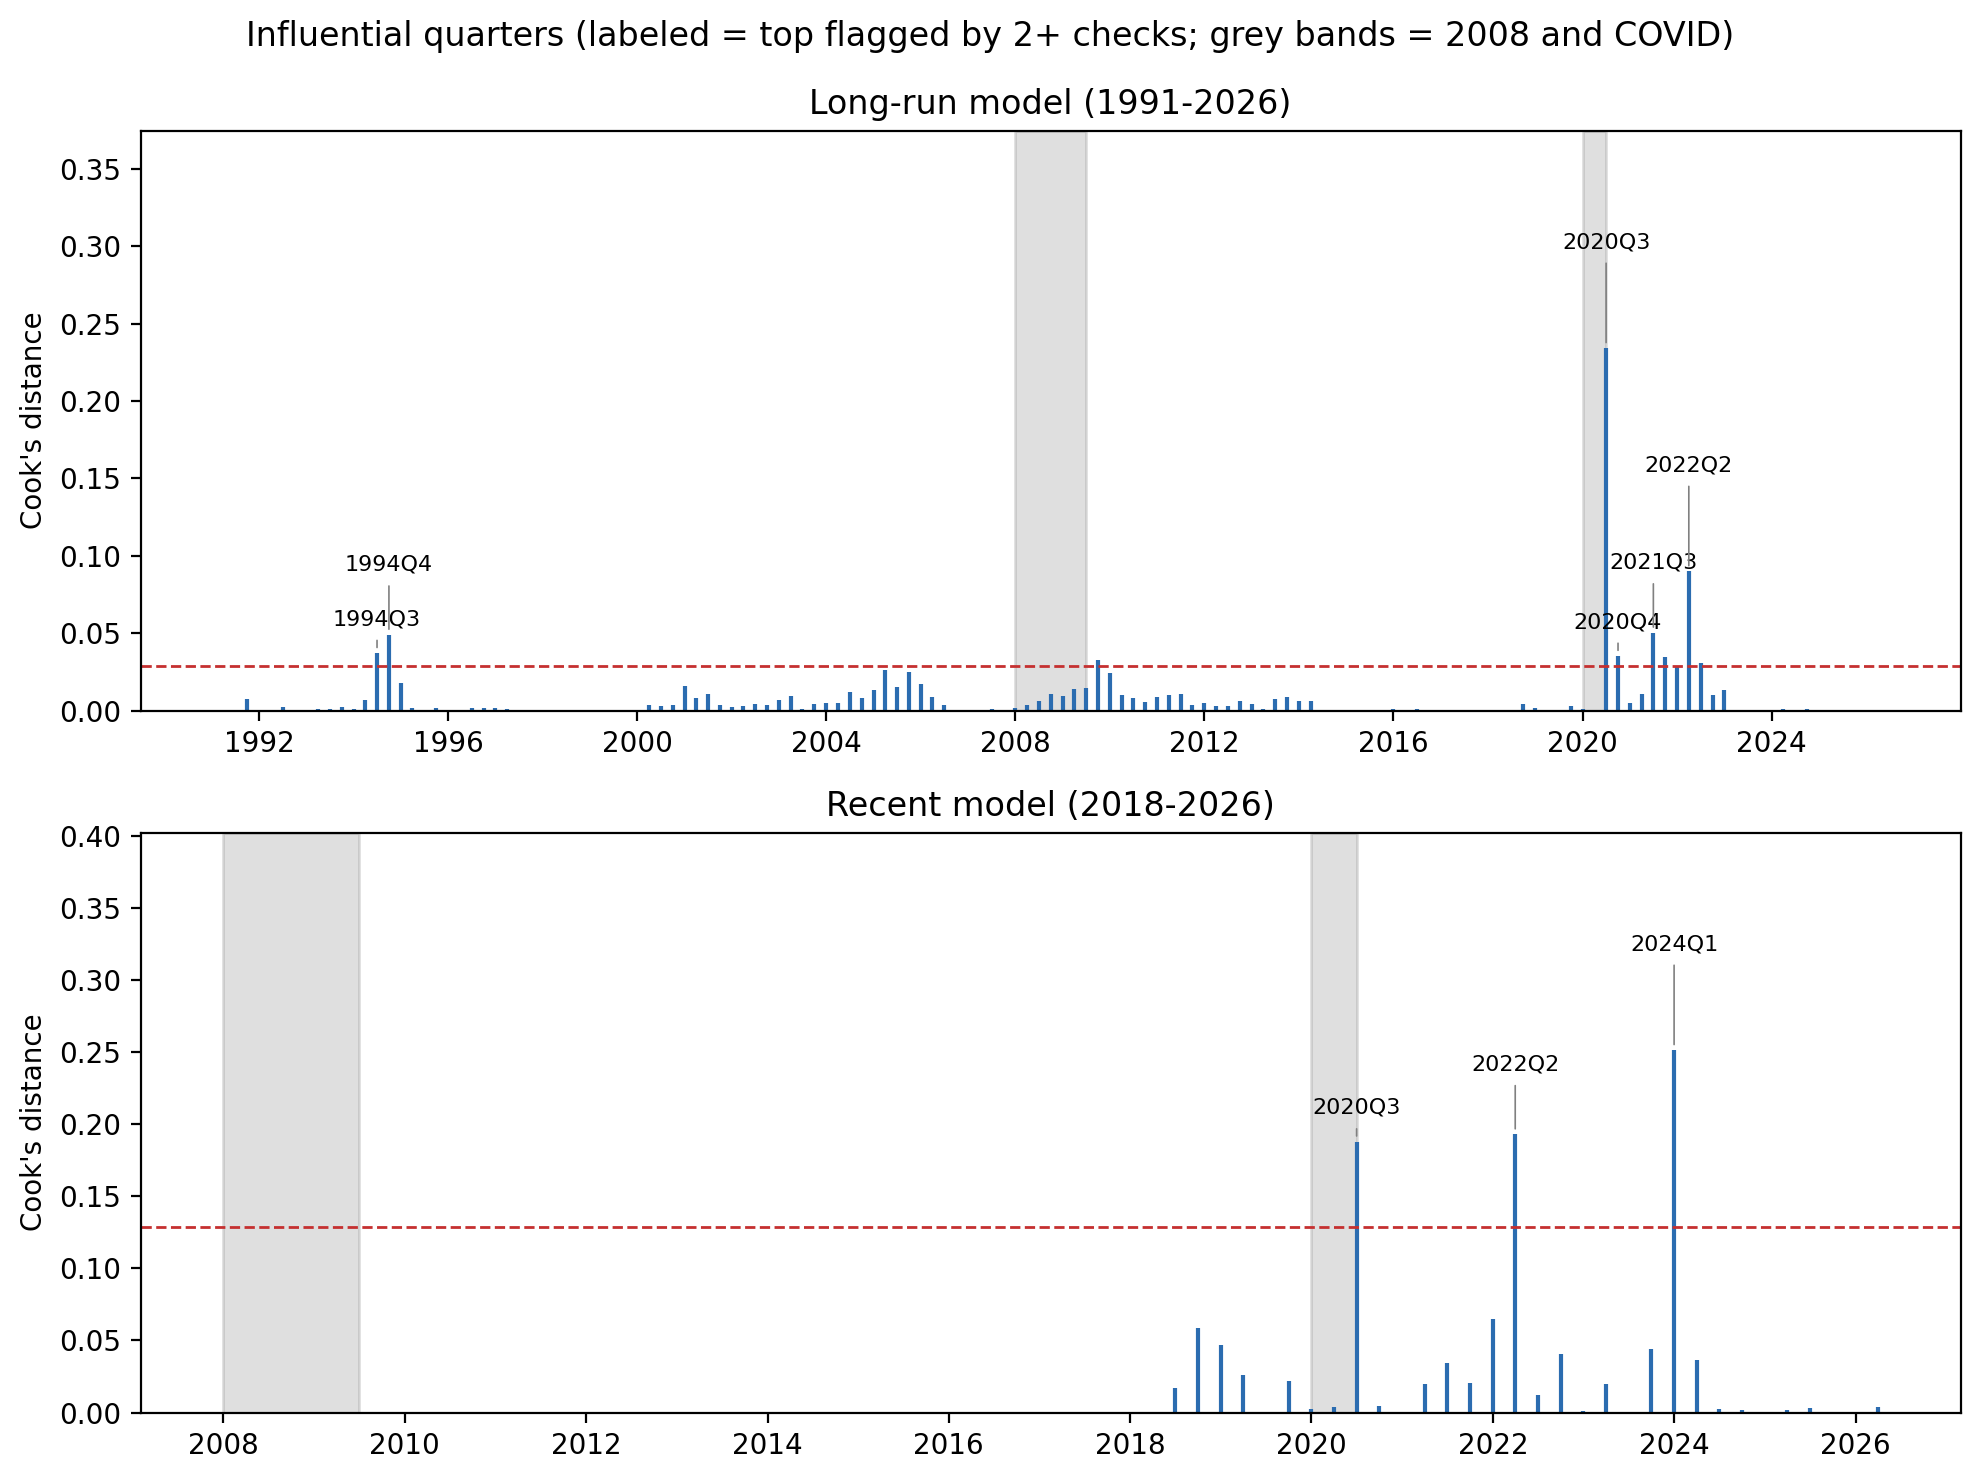

Saved figure: 05_influential_quarters.png


In [15]:
# Figure 5: Cook's distance by quarter, labeling the most influential flagged quarters
MAX_LABELS = 6          # labels per panel; lower this if the labels crowd together

fig, axes = plt.subplots(2, 1, figsize=(10, 7.5))
for ax, (name, label) in zip(axes, MODEL_LABELS.items()):
    c = influence[influence["model"] == name]
    d = to_dates(c["quarter"])
    add_shading(ax)
    ax.vlines(d, 0, c["cooks_d"], color=BLUE)
    ax.axhline(4 / len(c), color=RED, ls="--", lw=1)             # 4/n rule of thumb

    # Label the top flagged quarters, staggered at three heights so neighbors do not overlap
    lab = c[c["n_flags"] >= 2].nlargest(MAX_LABELS, "cooks_d").sort_values("quarter")
    for i, (_, r) in enumerate(lab.iterrows()):
        level = i % 3
        ax.annotate(r["quarter"], (to_dates([r["quarter"]])[0], r["cooks_d"]),
                    xytext=(0, 10 + level * 13), textcoords="offset points",
                    ha="center", fontsize=8,
                    arrowprops=dict(arrowstyle="-", lw=0.6, color="grey"))

    ax.set_ylim(0, c["cooks_d"].max() * 1.6)                     # headroom so labels fit
    ax.set_title(label)
    ax.set_ylabel("Cook's distance")
fig.suptitle("Influential quarters (labeled = top flagged by 2+ checks; grey bands = 2008 and COVID)")
fig.tight_layout()
save_fig(fig, "23_influential_quarters")

### 9b. Do the results depend on the crisis periods?
Each model is refit three ways:

1. **Baseline:** as originally fit.
2. **With crisis dummies:** adds 0/1 indicators for the 2007Q4-2009Q2 recession and the 2020Q1-2022Q4 pandemic period. All quarters are kept; the dummies absorb the average shift in price growth during those periods, and the predictor effects are re-estimated. This is the preferred check because the recent model has only ~31 quarters.
3. **Crisis quarters dropped:** a stricter comparison. The recent model falls to roughly 19 quarters, and dropping rows leaves gaps in time that the Newey-West calculation treats as consecutive, so read this version loosely.

**How to read the results:** if signs and rough sizes hold, the result is not driven by crisis periods. If a coefficient shrinks toward zero or flips, the association depends on that episode. Compare coefficients and confidence intervals, not only p-values, because dropping quarters also shrinks the sample.

In [16]:
def crisis_dummies(index):
    """0/1 indicator columns for each crisis window (omitted if the sample never enters it)."""
    d = pd.DataFrame(index=index)
    for col, (s, e) in CRISIS.items():
        d[col] = ((index >= pd.Period(s, "Q")) & (index <= pd.Period(e, "Q"))).astype(int)
    return d.loc[:, d.sum() > 0]


sens_rows = []
for name, m in models.items():
    y, X = m["y"], m["X"]
    d = crisis_dummies(y.index)
    keep = ~d.any(axis=1).values                      # quarters outside every crisis window
    sens_rows += [tidy(fit_model(y, X), "Baseline", name),
                  tidy(fit_model(y, pd.concat([X, d], axis=1)), "With crisis dummies", name),
                  tidy(fit_model(y[keep], X[keep]), "Crisis quarters dropped", name)]
sens = pd.concat(sens_rows, ignore_index=True)
sens.to_csv(TABLE_DIR / "09_outlier_sensitivity.csv", index=False)

is_dummy = sens["term"].str.startswith(("recession", "pandemic"))
pred = sens[~is_dummy & (sens["term"] != "const")]

# Predictor coefficients and p-values under each version
pivot = pred.pivot_table(index=["model", "term"], columns="spec",
                         values=["coefficient", "p_value"], sort=False)
pivot.to_csv(TABLE_DIR / "13_outlier_sensitivity_pivot.csv")
print("Predictor coefficients and p-values by version:")
print(pivot.round(3).to_string())

# How far price growth ran from the model's prediction during each crisis period
shifts = sens[is_dummy][["model", "term", "coefficient", "ci_95_low", "ci_95_high", "p_value"]]
shifts.to_csv(TABLE_DIR / "01_crisis_period_shifts.csv", index=False)
print("\nCrisis-period shifts (pp of HPI growth, controlling for the predictors):")
print(shifts.round(3).to_string(index=False))

Predictor coefficients and p-values by version:
                                       coefficient                                              p_value                                            
spec                                      Baseline With crisis dummies Crisis quarters dropped Baseline With crisis dummies Crisis quarters dropped
model    term                                                                                                                                      
long_run unemployment_rate_yoy_pp_lag1     -0.9160             -0.8330                 -0.1720   0.1420              0.0170                  0.9070
         mortgage_rate_yoy_pp_lag0          1.5640              1.1860                  0.8700   0.0160              0.0250                  0.1910
recent   unemployment_rate_yoy_pp_lag1     -1.0060             -1.3510                  4.9650   0.0140              0.0000                  0.3470
         mortgage_rate_yoy_pp_lag0          1.8990              

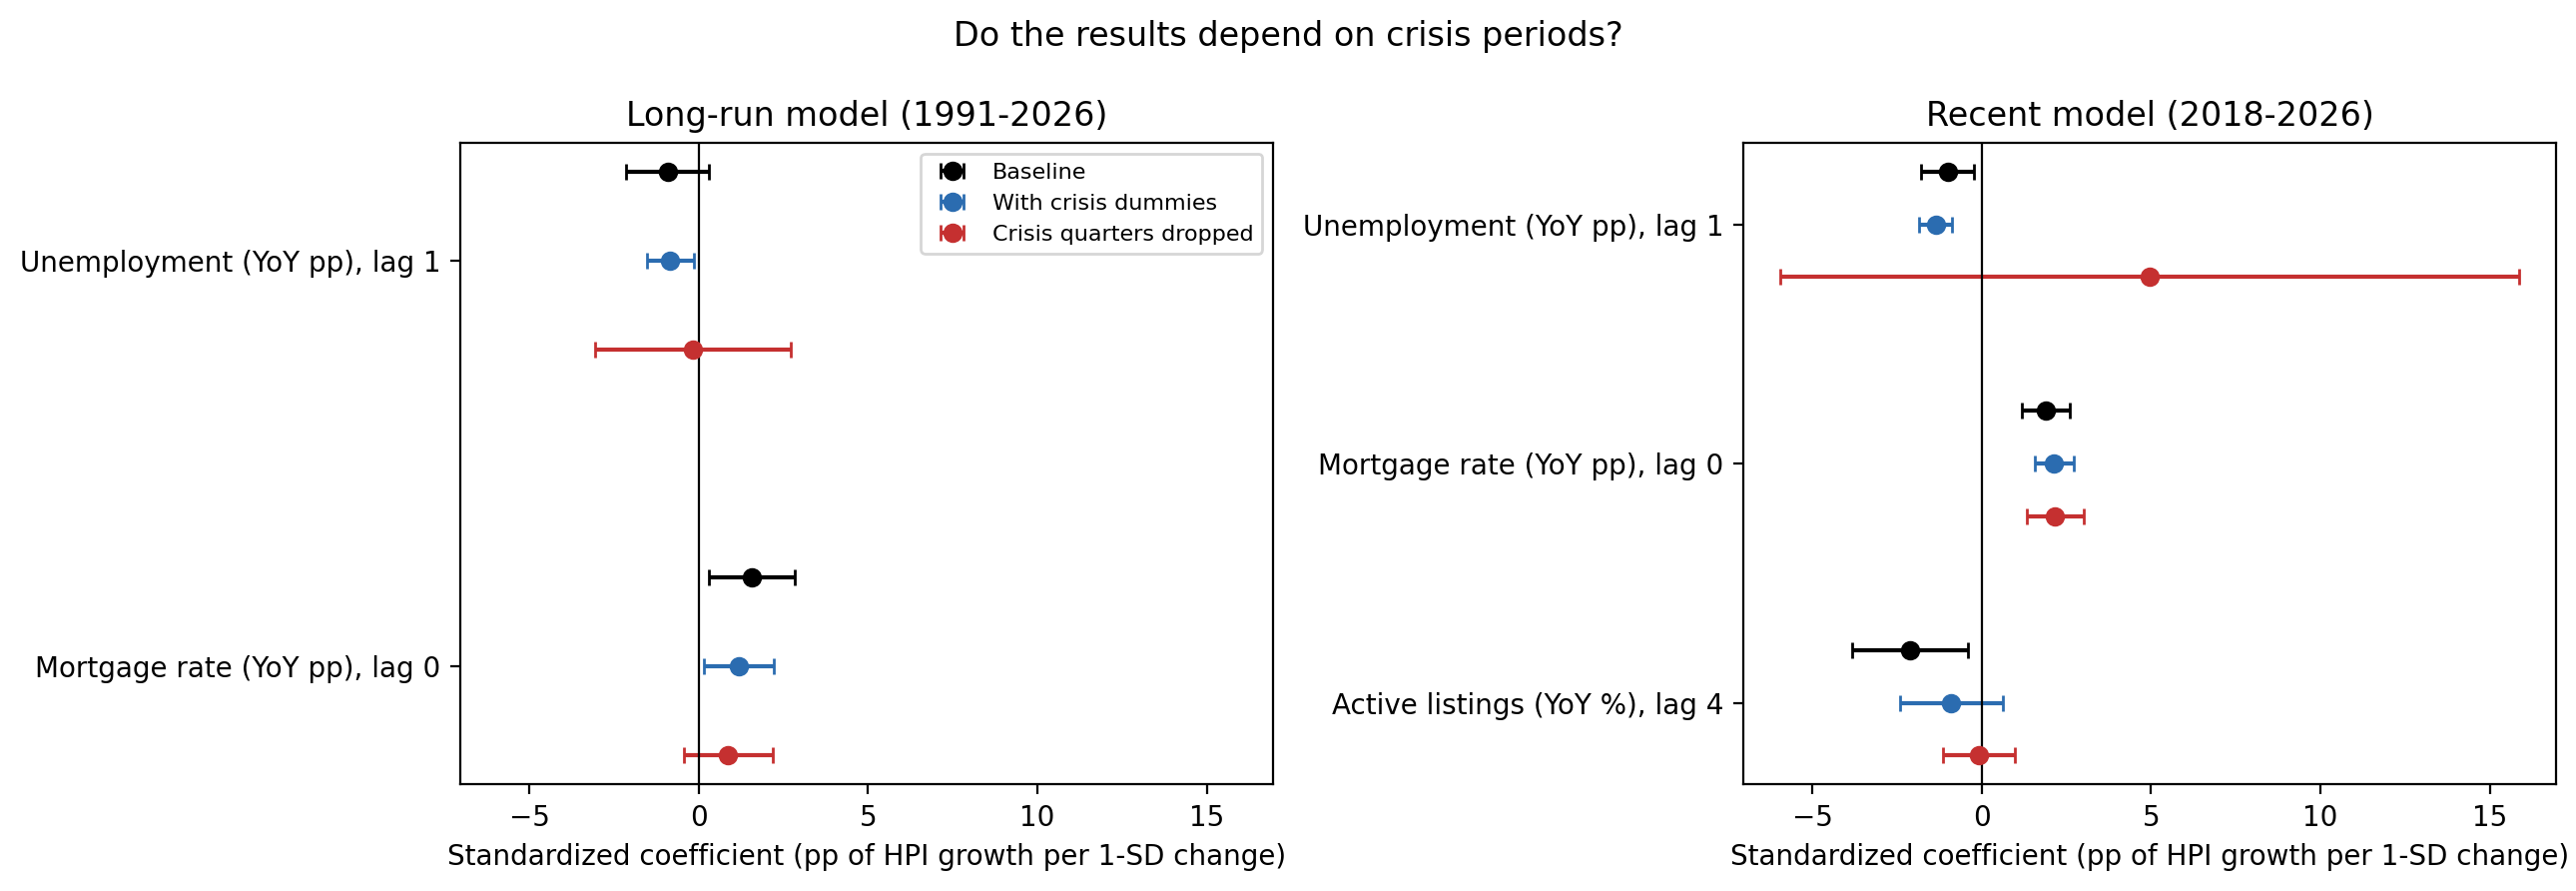

Saved figure: 06_outlier_sensitivity.png


In [17]:
# Figure 6: do the coefficients move when crisis periods are handled?
SPEC_COLORS = {"Baseline": "black", "With crisis dummies": BLUE, "Crisis quarters dropped": RED}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for ax, (name, label) in zip(axes, MODEL_LABELS.items()):
    t = pred[pred["model"] == name]
    terms = list(dict.fromkeys(t["term"]))[::-1]
    for i, term in enumerate(terms):
        for s, (spec, color) in enumerate(SPEC_COLORS.items()):
            r = t[(t["term"] == term) & (t["spec"] == spec)].iloc[0]
            ax.errorbar(r["coefficient"], i + (1 - s) * 0.22,          # offset so the three versions do not overlap
                        xerr=[[r["coefficient"] - r["ci_95_low"]], [r["ci_95_high"] - r["coefficient"]]],
                        fmt="o", color=color, capsize=3, label=spec if i == 0 else None)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_yticks(range(len(terms)))
    ax.set_yticklabels([pretty_term(x) for x in terms])
    ax.set_title(label)
    ax.set_xlabel("Standardized coefficient (pp of HPI growth per 1-SD change)")
axes[0].legend(fontsize=8, loc="best")
fig.suptitle("Do the results depend on crisis periods?")
fig.tight_layout()
save_fig(fig, "24_outlier_sensitivity")

## 10. Final results tables
The two tables requested by the project's quantifiable goal: each model's sample size, selected lags, coefficients, 95% confidence intervals, p-values, R-squared, adjusted R-squared, and VIF.

In [18]:
# Predictor-level table: coefficient, 95% CI, p-value, rank, VIF
final = results.copy()
final["Predictor"] = final["term"].map(pretty_term)
final["Coefficient"] = final["std_coefficient"].round(3)
final["95% CI"] = [f"[{lo:.2f}, {hi:.2f}]" for lo, hi in zip(final["ci_95_low"], final["ci_95_high"])]
final["p-value"] = final["p_value"].map(fmt_p)
final["Rank"] = final["rank"].apply(lambda r: "" if pd.isna(r) else int(r))
final["VIF"] = final["VIF"].apply(lambda v: "" if pd.isna(v) else f"{v:.2f}")
final = final[["model", "Predictor", "Coefficient", "95% CI", "p-value", "Rank", "VIF"]]
final.to_csv(TABLE_DIR / "06_final_results_table.csv", index=False)
save_table_png(final, "12_final_results_table", "Regression results (standardized predictors, Newey-West SEs)")

# Model-level table: sample size, selected lags, R-squared, adjusted R-squared
model_level = summary.copy()
model_level["selected_lags"] = [", ".join(pretty_term(c) for c in models[n]["X"].columns)
                                for n in model_level["model"]]
model_level["R2"] = model_level["R2"].round(3)
model_level["adj_R2"] = model_level["adj_R2"].round(3)
model_level.to_csv(TABLE_DIR / "04_final_model_summary.csv", index=False)
save_table_png(model_level[["model", "n_quarters", "R2", "adj_R2", "n_significant_predictors"]],
               "05_final_model_summary", "Model fit summary")

final

Saved table image: final_results_table.png
Saved table image: final_model_summary.png


,model,Predictor,Coefficient,95% CI,p-value,Rank,VIF
0,long_run,Intercept,4.4940,"[2.76, 6.23]",<0.001,,
1,long_run,"Mortgage rate (YoY pp), lag 0",1.5640,"[0.30, 2.83]",0.016,1,1.04
2,long_run,"Unemployment (YoY pp), lag 1",-0.9160,"[-2.14, 0.31]",0.142,2,1.04
3,recent,Intercept,7.0170,"[5.60, 8.44]",<0.001,,
4,recent,"Active listings (YoY %), lag 4",-2.1070,"[-3.81, -0.40]",0.017,1,1.32
5,recent,"Mortgage rate (YoY pp), lag 0",1.8990,"[1.19, 2.60]",<0.001,2,1.31
6,recent,"Unemployment (YoY pp), lag 1",-1.0060,"[-1.79, -0.22]",0.014,3,1.17


## 11. Save the software environment and list outputs
The versions used for this run are saved for reproducibility. The last cell writes `OUTPUT/evaluation_results.zip`, containing only the six evaluation figures and fourteen evaluation table/environment files listed below. Paths inside the archive retain the `OUTPUT/` prefix. In Colab, the archive is also downloaded.

In [ ]:
# Record the software versions used for this run
with open(TABLE_DIR / "14_evaluation_environment.txt", "w") as f:
    f.write(f"Python {platform.python_version()}\n")
    f.write(f"numpy {np.__version__}\npandas {pd.__version__}\n")
    f.write(f"statsmodels {statsmodels.__version__}\nmatplotlib {matplotlib.__version__}\n")

# Explicit manifest: exclude preprocessing/model-fitting outputs and unrelated files.
evaluation_figures = [FIG_DIR / name for name in [
    "19_actual_vs_fitted.png",
    "20_coefficient_plot.png",
    "21_lag_stability.png",
    "22_mortgage_vs_hpi_growth.png",
    "23_influential_quarters.png",
    "24_outlier_sensitivity.png",
]]
evaluation_tables = [TABLE_DIR / name for name in [
    "01_crisis_period_shifts.csv",
    "02_diagnostics.csv",
    "03_equal_strength_tests.csv",
    "04_final_model_summary.csv",
    "05_final_model_summary.png",
    "06_final_results_table.csv",
    "07_flagged_quarters.csv",
    "08_influence_measures.csv",
    "09_outlier_sensitivity.csv",
    "10_robustness_checks.csv",
    "11_robustness_p_values.csv",
    "12_final_results_table.png",
    "13_outlier_sensitivity_pivot.csv",
    "14_evaluation_environment.txt",
]]
evaluation_files = evaluation_figures + evaluation_tables

print("Figures:")
for p in evaluation_figures:
    print("  ", p.name)
print("Tables and environment:")
for p in evaluation_tables:
    print("  ", p.name)


In [ ]:
# Zip only the files made by this notebook (and download them when running in Colab).
missing = [str(p) for p in evaluation_files if not p.is_file()]
if missing:
    raise FileNotFoundError(f"Missing evaluation outputs; run all preceding cells first: {missing}")

zip_path = OUTPUT_DIR / "evaluation_results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in evaluation_files:
        z.write(p, arcname=str(p.relative_to(OUTPUT_DIR.parent)))   # keeps OUTPUT/... paths
print("Created:", zip_path)

if IN_COLAB:
    from google.colab import files
    files.download(str(zip_path))